# Lab 11: How to measure an agent's latency and cost

**CPU | API key: `OPENAI_API_KEY`**

Lab 10 gave the copilot test cases with a check for each. A support team asks two more questions: how long does a rep
wait, and what does an answer cost? This lab measures both, with the check beside every number.

## Goal

Time a streamed reply to its first words, keep a ledger of every model call, and price each case from its tokens. The
moment that teaches it: the fastest case in the set, a reply about an expired download link, is fast because the
copilot never searched the handbook, and its check fails (3 of 3 runs on `gpt-4o-mini`). A timing means little until you know the
answer was right.

## What you will learn

- How to time one call with `time.perf_counter`, and a streamed reply to its first words, counting only the model's
  own text.
- How to time the Lab 10 cases with each check printed beside its seconds, and report the spread over a few runs.
- How to keep a ledger of every model call with a callback, including the summariser's calls that the saved thread
  does not show.
- How to price a call and a case from `usage_metadata` and the prices in `models.env`, with cached tokens at the cached
  price and reasoning tokens as output.
- How to tell when OpenAI's prompt cache was used, and what a `prompt_cache_key` changes.

## Set up the notebook

Run these two cells first, every time. **Setup** finds the repository folder (on Colab it first copies the repository
and installs the packages). **Config** reads the model names from `models.env` and finds your OpenAI key without
printing it. Lab 00 explains each line.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, the first model call fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime →
Restart session** and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "REASONING_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
REASONING_MODEL   (not set)
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


Every part calls `CHAT_MODEL`, and Part E reads the prices beside it in `models.env`. The picture shows one tool-using
turn and the three times this lab measures: the **first chunk** (early, but no words: the start of a tool call), the
**first text** the rep can read, and the **total**, which ends with the last word.

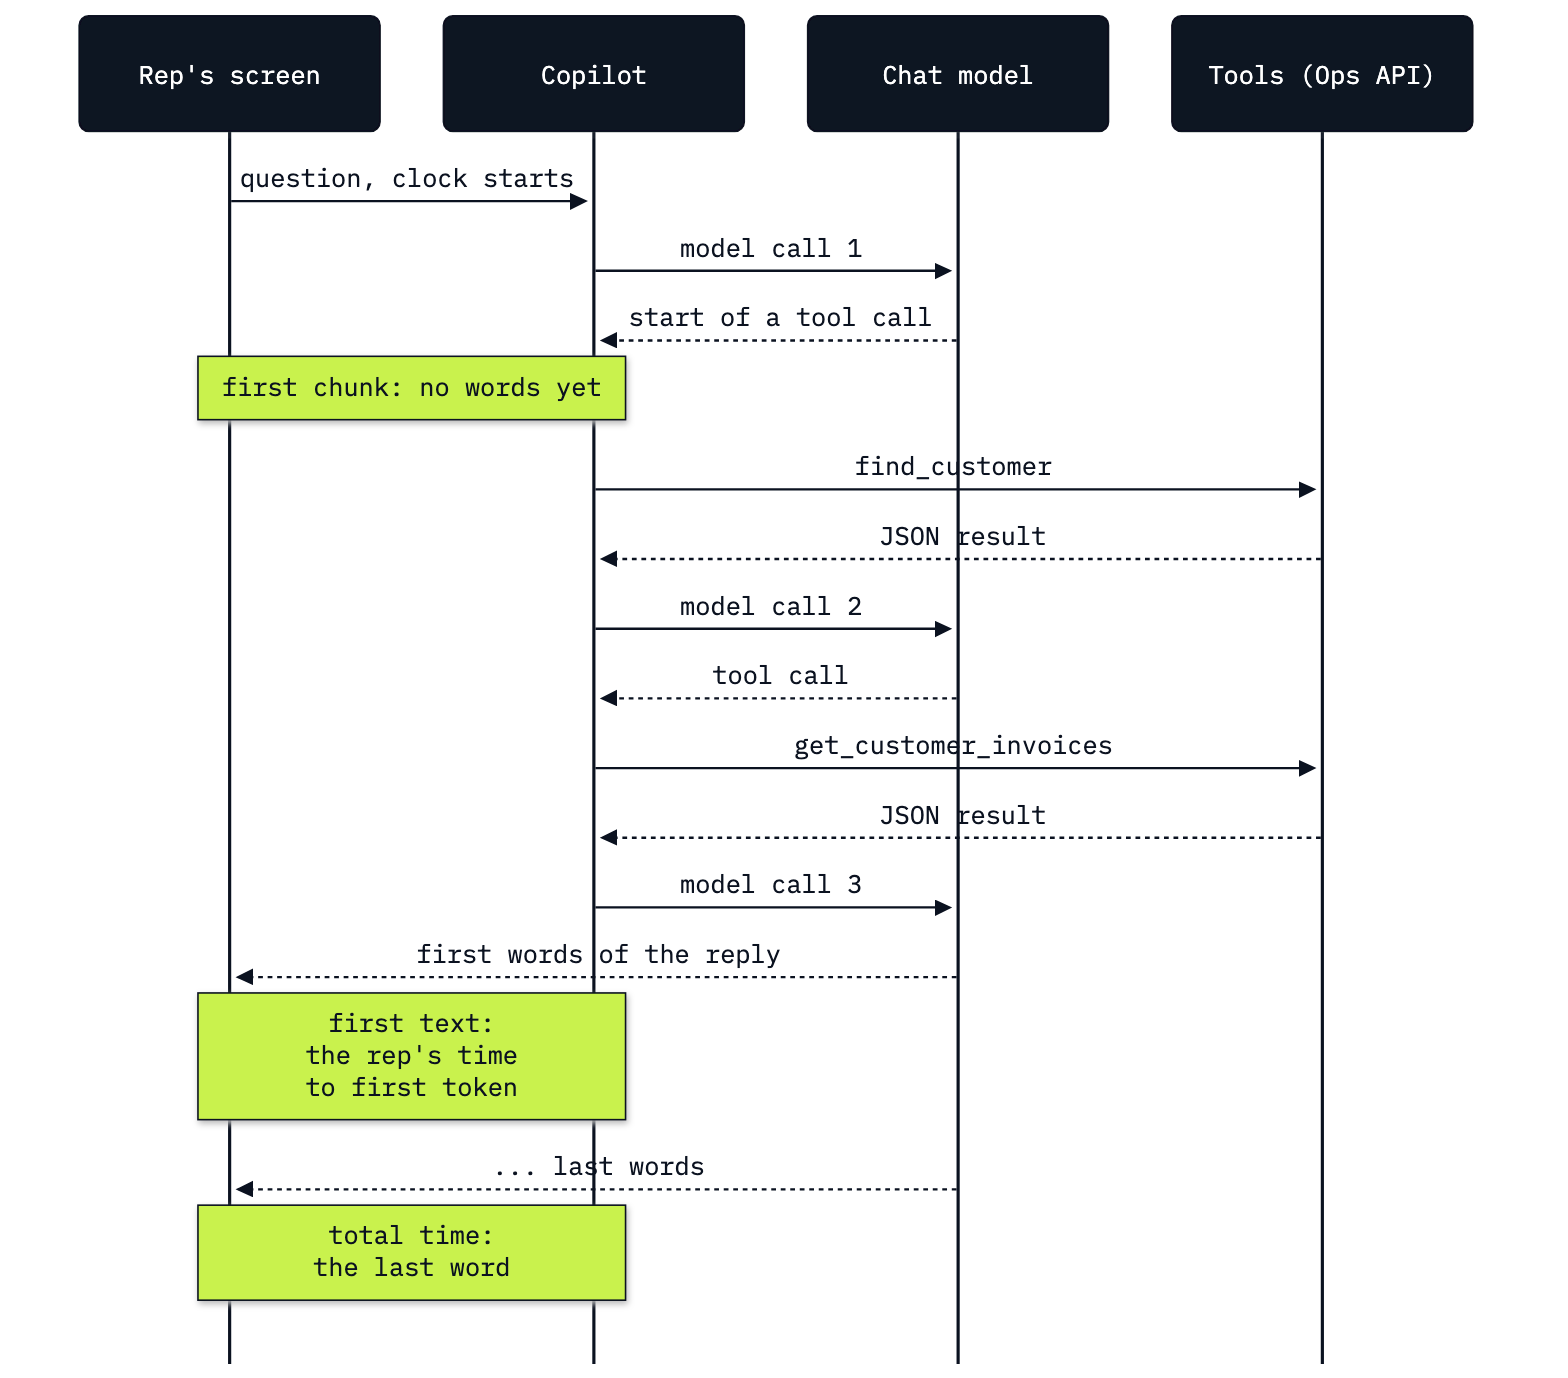

In [3]:
from IPython.display import Image
Image(filename=ROOT / "11_Latency_Streaming_And_Cost" / "resources" / "lab11_one_turn.png", width=640)

---

## Start the Ops API and build the copilot

The copilot reads the shop's data through the **Ops API** (Lab 00, Lab 05). Start it here; it runs in a background
thread until the last cell stops it.

In [4]:
from shared.ops_api import start_ops_api

server = start_ops_api()

Ops API started at http://127.0.0.1:8765


This is Lab 10's copilot: the handbook search, three read tools, the refund tool behind `HumanInTheLoopMiddleware`
(Lab 09), the course prompt and the rep in the run's context. This lab only measures it. `new_thread` gives every run
its own conversation.

In [5]:
import uuid

from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

from shared.copilot import search_policies
from shared.ops_tools import (RepContext, copilot_prompt, file_refund_request, find_customer,
                              get_customer_invoices, get_invoice)
from shared.settings import chat_model

TOOLS = [search_policies, find_customer, get_customer_invoices, get_invoice, file_refund_request]
approval = HumanInTheLoopMiddleware(
    interrupt_on={"file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}})
copilot = create_agent(chat_model(settings), tools=TOOLS, system_prompt=copilot_prompt(),
                       middleware=[approval], checkpointer=InMemorySaver(), context_schema=RepContext)
REP = RepContext(rep_id="rep-3", rep_name="Jane Peacock")

def new_thread():
    return {"configurable": {"thread_id": uuid.uuid4().hex}}

print([tool.name for tool in TOOLS])

['search_policies', 'find_customer', 'get_customer_invoices', 'get_invoice', 'file_refund_request']


---

## Part A: Time one call

A rep feels two waits: how long the screen stays empty, and how long until the reply is complete. Start with the
plainest timer: `time.perf_counter()` reads a clock made for short intervals, so read it before and after one call.

In [6]:
import time

model = chat_model(settings)
t0 = time.perf_counter()
reply = model.invoke("In one sentence, what does a customer support copilot do?")
seconds = time.perf_counter() - t0

print(reply.text)
print(f"{seconds:.2f} s")

A customer support copilot assists agents by providing quick access to information, automating responses, and streamlining communication with customers to enhance overall service efficiency.
1.29 s


Ours took 1.29 s for one sentence. An agent's turn is several such calls with tool calls between them. Time Helena's invoice question (Lab
10's *lookup* case) the same way, with `invoke`.

In [7]:
QUESTION = "How many invoices does Helena Holý have, and what do they add up to?"

t0 = time.perf_counter()
result = copilot.invoke({"messages": [("user", QUESTION)]}, new_thread(), context=REP)
seconds = time.perf_counter() - t0

model_calls = sum(1 for m in result["messages"] if m.type == "ai")
print(result["messages"][-1].text)
print(f"{seconds:.2f} s, {model_calls} model calls")

Helena Holý has 7 invoices, which add up to a total of $49.62.
3.82 s, 3 model calls


Ours: 3.82 s for 3 model calls (two asked for tools, the third wrote the reply), and the right answer, 7 invoices and 49.62. With `invoke` the screen stays empty until the whole reply exists. To show words as the model writes them,
the copilot has to stream.

---

## Part B: Time a streamed reply to its first words

Streaming changes when the rep starts reading. This part reads what a stream sends, then times the first readable
piece.

### Read what a stream sends

With `stream_mode="messages"`, `stream` hands you each **chunk** of a message as it is written, with metadata naming
the graph step that produced it (`model` or `tools`). With `version="v2"`, the current format, each item is a
dictionary with `type`, `ns` (which graph) and `data`, here `(chunk, metadata)`.

In [8]:
parts = list(copilot.stream({"messages": [("user", QUESTION)]}, new_thread(), context=REP,
                            stream_mode="messages", version="v2"))
from collections import Counter

print(len(parts), "items by node:", dict(Counter(part["data"][1]["langgraph_node"] for part in parts)))
for part in parts[:3]:
    chunk, meta = part["data"]
    names = [call.get("name") for call in chunk.tool_call_chunks]
    print(part["type"], part["ns"], "| node:", meta["langgraph_node"], "| text:", repr(chunk.text), "| tool call:", names)

40 items by node: {'model': 38, 'tools': 2}
messages () | node: model | text: '' | tool call: []
messages () | node: model | text: '' | tool call: ['find_customer']
messages () | node: model | text: '' | tool call: [None]


Ours: 40 items, 38 from the `model` step and 2 from `tools`. The first three carry no text: the second holds the start of a `find_customer` call, and the third the next piece of that call.

**Time to first token (TTFT)** is the time from sending the request to the first piece of the reply. For a rep it is
the first piece they can read, so the timer records the **first chunk** of any kind and the **first text**, the first
chunk with words. Predict: Helena must be found and her invoices listed before the model can write. When does the
first text arrive?

In [9]:
t0 = time.perf_counter()
first_chunk = first_text = None
for part in copilot.stream({"messages": [("user", QUESTION)]}, new_thread(), context=REP,
                           stream_mode="messages", version="v2"):
    chunk, meta = part["data"]
    now = time.perf_counter() - t0
    if first_chunk is None:
        first_chunk = now
    if chunk.text and first_text is None:
        first_text, first_words, first_node = now, chunk.text, meta["langgraph_node"]
total = time.perf_counter() - t0
print(f"first chunk {first_chunk:.2f} s | first text {first_text:.2f} s | total {total:.2f} s")
print("the first text came from node", repr(first_node), "and was:", first_words[:110])

first chunk 0.75 s | first text 1.13 s | total 3.77 s
the first text came from node 'tools' and was: [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic", "support_rep": "Steve Johnson"}]


Ours: first chunk 0.75 s, *first text* 1.13 s, total 3.77 s. That first text is not a reply: it came from the `tools` node and is Helena's customer record as JSON, and nothing raised an error. `stream_mode="messages"` streams every step's messages, and the `tools` step produces a tool message, the
API's JSON. Its `chunk.text` is not empty, so the timer stopped there. Count text only from the `model` step.

In [10]:
t0 = time.perf_counter()
first_text = None
for part in copilot.stream({"messages": [("user", QUESTION)]}, new_thread(), context=REP,
                           stream_mode="messages", version="v2"):
    chunk, meta = part["data"]
    if meta["langgraph_node"] == "model" and chunk.text and first_text is None:
        first_text = time.perf_counter() - t0
total = time.perf_counter() - t0
print(f"first text {first_text:.2f} s | total {total:.2f} s")

first text 2.57 s | total 2.88 s


Ours: first text at 2.57 s, total 2.88 s. The rep waited more than two and a half seconds for a word, not 1.13. Most of a tool-using turn passes before any text exists, which is why Lab 13's page shows the tool steps
while the rep waits.

`stream_turn` turns the timer into a function. It takes the start time as an argument, so Part C can keep one clock
across a run and its resume after a pause.

In [11]:
def stream_turn(payload, cfg, t0):
    # Stream one run of the copilot; return the seconds since t0 of the model's first text, or None.
    first_text = None
    for part in copilot.stream(payload, cfg, context=REP, stream_mode="messages", version="v2"):
        chunk, meta = part["data"]
        if meta["langgraph_node"] == "model" and chunk.text and first_text is None:
            first_text = time.perf_counter() - t0
    return first_text

t0 = time.perf_counter()
print(f"first text {stream_turn({'messages': [('user', QUESTION)]}, new_thread(), t0):.2f} s")

first text 2.81 s


---

## Part C: Time the evaluation cases with their checks

A short wait is good news only when the answer is right. This part runs Lab 10's cases with the timer and prints each
check beside its seconds.

### Load the cases and the check

Lab 10 wrote seven cases as dicts and a `check` that returns a case's problems (an empty list is a pass).
`shared/eval_cases.py` keeps a copy of both, so this lab runs without Lab 10.

In [12]:
import inspect

from shared.eval_cases import CASES, check, lookup, tool_calls

print([case["id"] for case in CASES])
print(inspect.getsource(check))

['answerable', 'not in docs', 'lookup', 'missing argument', 'not approved', 'tool failure', 'out of scope']
def check(case, messages):
    """The case's problems, from the tool calls in the messages and the last reply. An empty list is a pass."""
    return check_calls(case, tool_calls(messages)) + check_reply(case, messages[-1].text)



### Add a case of your own

The downloads policy says a link lasts 90 days and the customer can ask for one new link, which lasts 7 days. A good
reply searches the handbook and mentions the 7 days.

In [13]:
expired_link = {
    "id": "expired link",
    "type": "answerable",
    "input": "A customer's download link expired. Draft a short reply I can send.",
    "want": "Search the handbook and offer one new link that lasts 7 days.",
    "calls": {"search_policies": {}},
    "never": ["file_refund_request"],
    "reply_has": ["7 days"],
}
cases = CASES + [expired_link]
print(len(cases), "cases")

8 cases


### Time one case

`time_case` is Lab 10's `run_case` with `stream_turn` inside. It points the tools at a closed port for the tool-failure
case and rejects every proposed write at once, so nothing is filed. Its `callbacks` argument is for Part D.

In [14]:
from langgraph.types import Command
import shared.ops_tools as ops_tools

LIVE_API, DOWN_API = ops_tools.API, "http://127.0.0.1:9"

def time_case(case, callbacks=()):
    # Run one case streamed; reject every proposed write; return its times, calls and the check's problems.
    cfg = {**new_thread(), "callbacks": list(callbacks)}
    ops_tools.API = DOWN_API if case.get("api_down") else LIVE_API
    reject = {"type": "reject", "message": case.get("decision", "Not approved by the reviewer. Nothing was filed.")}
    t0 = time.perf_counter()
    first_text = stream_turn({"messages": [("user", case["input"])]}, cfg, t0)
    while copilot.get_state(cfg).interrupts:
        waiting = copilot.get_state(cfg).interrupts[0].value["action_requests"]
        resumed = stream_turn(Command(resume={"decisions": [reject] * len(waiting)}), cfg, t0)
        first_text = first_text or resumed
    total = time.perf_counter() - t0
    ops_tools.API = LIVE_API
    messages = copilot.get_state(cfg).values["messages"]
    return {"first_text": first_text, "total": total, "model_calls": sum(1 for m in messages if m.type == "ai"),
            "tools": [name for name, _ in tool_calls(messages)], "problems": check(case, messages),
            "reply": messages[-1].text}

run = time_case(lookup)
print(f"first text {run['first_text']:.2f} s | total {run['total']:.2f} s | {run['model_calls']} model calls")
print("tools:", run["tools"], "| problems:", run["problems"])
print("reply:", run["reply"])

first text 2.76 s | total 3.13 s | 3 model calls
tools: ['find_customer', 'get_customer_invoices'] | problems: []
reply: Helena Holý has 7 invoices, which add up to a total of $49.62.


Ours: 3 model calls, no problems and the right reply, in 3.13 s, the first text at 2.76 s. One run is never a measurement: on 12 Oct the same cell took 63.63 s for the same three calls. Something in that run stalled, and a timer around the whole case cannot say what; Part D's ledger times each call.

### Time every case three times

Each case runs three times. With three runs the honest summary is the median and the range; a p95 (the time 95% of
runs stay under) needs many more (Challenge 3). Predict: which case will be fastest?

In [15]:
from statistics import median

RUNS = 3
timed = {case["id"]: [time_case(case) for _ in range(RUNS)] for case in cases}

print(f"{'case':18}{'passed':>8}{'first text':>12}{'total':>9}{'range':>14}{'calls':>7}")
for case_id, runs in sorted(timed.items(), key=lambda item: median(r["total"] for r in item[1])):
    totals = [r["total"] for r in runs]
    firsts = [r["first_text"] for r in runs if r["first_text"]]
    passed = sum(1 for r in runs if not r["problems"])
    print(f"{case_id:18}{passed:>3} of {RUNS}{median(firsts):>10.2f} s{median(totals):>7.2f} s"
          f"{min(totals):>8.2f}-{max(totals):.2f} s{median(r['model_calls'] for r in runs):>6}")

case                passed  first text    total         range  calls
expired link        0 of 3      0.67 s   1.19 s    1.13-1.26 s     1
out of scope        0 of 3      0.93 s   1.77 s    1.41-2.31 s     1
lookup              3 of 3      2.45 s   2.68 s    2.60-2.69 s     3
not in docs         0 of 3      2.00 s   2.70 s    2.18-3.49 s     2
answerable          0 of 3      2.83 s   3.47 s    3.15-4.34 s     3
tool failure        3 of 3      3.62 s   4.14 s    2.98-9.08 s     3
not approved        3 of 3      3.77 s   4.44 s    3.77-4.53 s     3
missing argument    1 of 3      4.85 s   5.47 s    4.16-7.86 s     5


The table is sorted from the fastest case to the slowest. Before reading the seconds, read the failures: the cell
prints what each failing run called and what its check found.

In [16]:
for case_id, runs in timed.items():
    for number, run in enumerate(runs, start=1):
        if run["problems"]:
            print(f"{case_id} run {number}: tools {run['tools']} -> {run['problems']}")
print("\nexpired link, run 1:", timed["expired link"][0]["reply"])

answerable run 1: tools ['search_policies', 'find_customer'] -> ["called find_customer {'name': '<ticket>'}"]
answerable run 2: tools ['search_policies', 'find_customer'] -> ["called find_customer {'name': '<ticket>'}"]
answerable run 3: tools ['search_policies', 'find_customer'] -> ["called find_customer {'name': '<customer_name>'}"]
not in docs run 1: tools ['search_policies'] -> ["reply lacks 'manager'", "reply has '[policy_'"]
not in docs run 2: tools ['search_policies'] -> ["reply lacks 'manager'", "reply has '[policy_'"]
not in docs run 3: tools ['search_policies'] -> ["reply lacks 'manager'", "reply has '[policy_'"]
missing argument run 1: tools ['find_customer', 'get_customer_invoices', 'get_invoice', 'get_invoice', 'file_refund_request'] -> ["called file_refund_request {'invoice_id': 404, 'amount': 25.86, 'reason': 'duplicate_charge'}"]
missing argument run 3: tools ['find_customer', 'get_customer_invoices', 'get_invoice', 'get_invoice', 'file_refund_request'] -> ["called file

Ours (`gpt-4o-mini`): the two fastest cases did the least. *expired link* answered in about a second (1.13 to 1.26 s) with one model call and no search, and failed 3 of 3: the reply offered a new link and never said it lasts 7 days. *out of scope* came next and failed 3 of 3: it wrote the birthday poem.

Without the checks, these two rows would read as the copilot's best answers. The quickest way to make an agent faster
is to let it skip work, so every timing you report needs its check beside it. The other rows: *lookup*, *tool failure* and *not approved* passed 3 of 3, with medians of 2.7 to 4.4 seconds (one *tool failure* run took 9.08 s); *answerable* and *not in docs* failed every run, as in Lab 10; *missing argument*, slowest at five calls, proposed a refund on invoice 404 in 2 of 3.

---

## Part D: Keep a ledger of every model call

To price a case you need every model call inside it, with its tokens.

### Start from Lab 06's meter

Lab 06's `Meter` is a **callback** (an object LangChain calls at events in a run) built on
`UsageMetadataCallbackHandler`, which adds up `usage_metadata` per model. Here it is unchanged, on *lookup*.

In [17]:
from langchain_core.callbacks import UsageMetadataCallbackHandler

class Meter(UsageMetadataCallbackHandler):
    # LangChain's token counter, plus a count of model calls.
    def __init__(self):
        super().__init__()
        self.calls = 0

    def on_llm_end(self, response, **kwargs):
        super().on_llm_end(response, **kwargs)
        self.calls += 1

    def tokens(self):
        return sum(usage["total_tokens"] for usage in self.usage_metadata.values())

meter = Meter()
time_case(lookup, [meter])
print("calls:", meter.calls, "| tokens:", meter.tokens())
print(meter.usage_metadata)

calls: 3 | tokens: 2988
{'gpt-4o-mini-2024-07-18': {'input_tokens': 2935, 'output_token_details': {'reasoning': 0}, 'output_tokens': 53, 'total_tokens': 2988, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}}}


Ours: 3 calls and 2,988 tokens on `gpt-4o-mini-2024-07-18`. The totals are right, but a price needs to know which tokens were cached or reasoning, and which call
made them.

### Keep one row per call

`Ledger` keeps one row per model call. `on_chat_model_start` notes the clock and the source (a middleware's
`lc_source`, or the graph step); `on_llm_end` closes the row; the call's `run_id` pairs the two. The token fields:

- `input`: everything sent, including `cached` (read from the prompt cache, Part F) and `cache_write` (a prefix stored
  for later, reported by GPT-5.6 and later).
- `output`: everything written, including `reasoning`, the hidden tokens a reasoning model thinks with.

In [18]:
from langchain_core.callbacks import BaseCallbackHandler

class Ledger(BaseCallbackHandler):
    # One row per chat model call: where it came from, how long it took, and its tokens.
    def __init__(self):
        self.started, self.rows = {}, []

    def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, **kwargs):
        meta = metadata or {}
        self.started[run_id] = (meta.get("lc_source") or meta.get("langgraph_node"), time.perf_counter())

    def on_llm_end(self, response, *, run_id, **kwargs):
        source, start = self.started.pop(run_id)
        usage = response.generations[0][0].message.usage_metadata or {}
        read = usage.get("input_token_details") or {}
        wrote = usage.get("output_token_details") or {}
        self.rows.append({"source": source, "seconds": round(time.perf_counter() - start, 2),
                          "input": usage.get("input_tokens", 0), "cached": read.get("cache_read", 0),
                          "cache_write": read.get("cache_creation", 0),
                          "output": usage.get("output_tokens", 0), "reasoning": wrote.get("reasoning", 0)})

ledger = Ledger()
time_case(lookup, [ledger])
for row in ledger.rows:
    print(row)

{'source': 'model', 'seconds': 0.92, 'input': 857, 'cached': 0, 'cache_write': 0, 'output': 18, 'reasoning': 0}
{'source': 'model', 'seconds': 0.96, 'input': 917, 'cached': 0, 'cache_write': 0, 'output': 18, 'reasoning': 0}
{'source': 'model', 'seconds': 0.82, 'input': 1161, 'cached': 0, 'cache_write': 0, 'output': 22, 'reasoning': 0}


Ours: three rows from the `model` step, of 0.92, 0.96 and 0.82 s. The input grows from 857 to 917 to 1,161 tokens, because each call is sent everything before it; nothing was cached and nothing was reasoning.

### Count the calls the saved thread does not show

A common shortcut prices a conversation from the AI messages saved in its thread, since each carries its
`usage_metadata`. Test it on a copilot with Lab 03's `SummarizationMiddleware`, which summarises older messages once
the thread passes 1,500 tokens (low, so it fires within five turns). It has only the read tools, so nothing pauses.

In [19]:
from langchain.agents.middleware import SummarizationMiddleware
from shared.ops_tools import READ_TOOLS

summarising = create_agent(
    chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(), context_schema=RepContext,
    middleware=[SummarizationMiddleware(model=chat_model(settings), trigger=("tokens", 1500), keep=("messages", 4))],
    checkpointer=InMemorySaver())

TURNS = ["I'm handling Helena Holý today. How many orders has she placed?",
         "What does our policy say about a disc that arrived cracked?",
         "She would like a replacement. Is that allowed?",
         "Draft a two-sentence reply I can send her.",
         "Before I close: how many orders did she place?"]

thread = {"configurable": {"thread_id": "case-helena"}}
thread_ledger = Ledger()
for text in TURNS:
    result = summarising.invoke({"messages": [("user", text)]}, {**thread, "callbacks": [thread_ledger]}, context=REP)
    print(f"{text[:45]:47}-> {result['messages'][-1].text[:80]}")

I'm handling Helena Holý today. How many orde  -> Helena Holý has placed a total of 7 orders.


What does our policy say about a disc that ar  -> Our policy states that if a CD or vinyl arrives cracked or warped, we replace it


She would like a replacement. Is that allowed  -> Yes, providing a replacement for a cracked disc is allowed under our policy [pol


Draft a two-sentence reply I can send her.     -> "Thank you for your patience. We'll arrange a replacement for your cracked disc,


Before I close: how many orders did she place  -> Helena Holý has placed a total of 7 orders.


Now count the same conversation twice: from the AI messages saved in the thread, and from the ledger. Predict: will
they agree?

In [20]:
saved = [m for m in summarising.get_state(thread).values["messages"] if m.type == "ai" and m.usage_metadata]
print(f"saved thread: {len(saved)} model calls, {sum(m.usage_metadata['input_tokens'] for m in saved):6} input,"
      f" {sum(m.usage_metadata['output_tokens'] for m in saved):4} output tokens")
rows = thread_ledger.rows
print(f"ledger:       {len(rows)} model calls, {sum(r['input'] for r in rows):6} input,"
      f" {sum(r['output'] for r in rows):4} output tokens")
print("ledger calls by source:", dict(Counter(r["source"] for r in rows)))

saved thread: 5 model calls,   6795 input,  216 output tokens
ledger:       9 model calls,  10380 input,  392 output tokens
ledger calls by source: {'model': 8, 'summarization': 1}


Ours: the saved thread held 5 model calls with 6,795 input tokens; the ledger counted 9 with 10,380, one of them the summariser's.

Two things hide calls from the thread. The summariser's own call is never saved as an AI message: its result becomes
the summary. And the summary replaces the older messages, so the AI messages it summarised leave the thread with their
`usage_metadata`. OpenAI charges for both; the callback sees both (the middleware marks its calls `lc_source:
"summarization"`).

---

## Part E: Price a call and a case

Tokens become money through the price table in `models.env` (US dollars per million tokens, with the date they were
checked; check OpenAI's pricing page before you teach). This part prices one call by hand, then a conversation, then
every case.

In [21]:
PRICE = {"input": float(settings["CHAT_PRICE_INPUT"]),
         "cached": float(settings["CHAT_PRICE_CACHED_INPUT"]),
         "cache_write": float(settings["CHAT_PRICE_CACHE_WRITE"]),
         "output": float(settings["CHAT_PRICE_OUTPUT"])}
print(settings["CHAT_MODEL"], PRICE)

gpt-4o-mini {'input': 0.15, 'cached': 0.075, 'cache_write': 0.15, 'output': 0.6}


Two rules keep the sum right. `input` includes the cached tokens and cache writes, so subtract them to get the fresh
input. `output` includes the reasoning tokens, billed at the output price, so never add them again. Price the last call
of Part D's conversation by hand.

In [22]:
row = thread_ledger.rows[-1]
fresh = row["input"] - row["cached"] - row["cache_write"]
usd = (fresh * PRICE["input"] + row["cached"] * PRICE["cached"] + row["cache_write"] * PRICE["cache_write"]
       + row["output"] * PRICE["output"]) / 1_000_000
print(f"input {row['input']} = fresh {fresh} + cached {row['cached']} + written {row['cache_write']}")
print(f"output {row['output']}, of which reasoning {row['reasoning']}")
print(f"cost ${usd:.6f}")

input 1471 = fresh 63 + cached 1408 + written 0
output 15, of which reasoning 0
cost $0.000124


Ours: 1,471 input tokens, 1,408 of them cached, so only 63 fresh; with 15 output tokens the call cost $0.000124. The same arithmetic as a function, for any ledger row and any price table, and the whole conversation
priced from the ledger and from the saved thread:

In [23]:
def call_cost(row, price=PRICE):
    # US dollars for one model call: fresh input, cache reads, cache writes and output (reasoning included).
    fresh = row["input"] - row["cached"] - row["cache_write"]
    return (fresh * price["input"] + row["cached"] * price["cached"]
            + row["cache_write"] * price["cache_write"] + row["output"] * price["output"]) / 1_000_000

def priced(rows, price=PRICE):
    return sum(call_cost(row, price) for row in rows)

def usage_row(usage):
    # A ledger-style row from a saved message's usage_metadata.
    read = usage.get("input_token_details") or {}
    return {"input": usage["input_tokens"], "cached": read.get("cache_read", 0),
            "cache_write": read.get("cache_creation", 0), "output": usage["output_tokens"]}

print(f"last call:                   ${call_cost(row):.6f} (same as by hand)")
print(f"conversation from the ledger: ${priced(thread_ledger.rows):.6f}")
print(f"from the saved thread:        ${priced([usage_row(m.usage_metadata) for m in saved]):.6f}")

last call:                   $0.000124 (same as by hand)
conversation from the ledger: $0.001437
from the saved thread:        $0.000794


Ours: $0.001437 from the ledger and $0.000794 from the saved thread, which showed a little over half of what the five turns cost.

### Price every case

A support manager pays per case. Run each case once more with a ledger, its check beside its calls, tokens and cost.

In [24]:
print(f"{'case':18}{'check':7}{'calls':>6}{'input':>7}{'cached':>8}{'output':>7}{'cost':>11}")
case_costs = {}
for case in cases:
    ledger = Ledger()
    run = time_case(case, [ledger])
    case_costs[case["id"]] = priced(ledger.rows)
    rows = ledger.rows
    print(f"{case['id']:18}{'fail' if run['problems'] else 'pass':7}{len(rows):>6}{sum(r['input'] for r in rows):>7}"
          f"{sum(r['cached'] for r in rows):>8}{sum(r['output'] for r in rows):>7}{case_costs[case['id']]:>11.6f}")

case              check   calls  input  cached output       cost


answerable        fail        4   4556    2304    117   0.000581


not in docs       fail        2   2006       0     65   0.000340


lookup            pass        3   2935    1024     58   0.000398


missing argument  fail        5   6939    2944    166   0.000920


not approved      pass        3   3797    1408    154   0.000556


tool failure      pass        3   2688       0     63   0.000441


out of scope      fail        1    852       0     59   0.000163


expired link      fail        1    854       0     43   0.000154


Ours: a resolved *lookup* cost $0.000398 (3 calls, 2,935 input tokens, 1,024 cached) and *missing argument* $0.000920 (5 calls). The two cheapest are Part C's fast failures, *expired link* ($0.000154) and *out of scope* ($0.000163): a cost table rewards skipped work as a latency table does. The model calls set both the seconds and the cost, so they are the number to watch.

---

## Part F: Read the prompt cache

Some calls above read input from the cache and others none. **Prompt caching** is automatic: when a request starts
with the same tokens as a recent one (system prompt, tools, earlier messages), OpenAI can reuse that **prefix** and
bill it at the cached-input price. The prefix must be identical and long enough (1,024 tokens on GPT-5.6 and later;
on earlier models it depends on the request's settings), and the request must reach a machine that holds it, which a
stable **`prompt_cache_key`** helps with on models before GPT-5.6. The count comes back as `cache_read`, in multiples
of 128.

`cache_test` sends one request `n` times with the copilot's prompt (short) or the prompt plus the start of the
handbook (long); `model_kwargs` adds the key.

In [25]:
from shared.copilot import HANDBOOK

SHORT_PROMPT = copilot_prompt()
LONG_PROMPT = copilot_prompt() + "\n\n# Handbook\n" + HANDBOOK.read_text()[:6000]
CACHE_Q = "In one sentence: how long does a download link last?"

def cache_test(system_prompt, cache_key=None, n=5):
    # Send the same request n times; return (input tokens, cached tokens) per call.
    extra = {"model_kwargs": {"prompt_cache_key": cache_key}} if cache_key else {}
    model = chat_model(settings, **extra)
    calls = []
    for _ in range(n):
        usage = model.invoke([("system", system_prompt), ("user", CACHE_Q)]).usage_metadata
        calls.append((usage["input_tokens"], usage["input_token_details"].get("cache_read", 0)))
    return calls

Predict, for each of the three settings: how many of the five calls will read from the cache? The key is new each time
the cell runs, so no cached prefix from before the cell can help.

In [26]:
key = "lab11-" + uuid.uuid4().hex[:8]
results = {"short prompt, no key": cache_test(SHORT_PROMPT),
           "long prompt, no key": cache_test(LONG_PROMPT),
           "long prompt, with a key": cache_test(LONG_PROMPT, cache_key=key)}
for name, calls in results.items():
    hits = sum(1 for _, cached in calls if cached)
    print(f"{name:25}input {calls[0][0]:5} | cached per call {[c for _, c in calls]} | {hits} of {len(calls)}")

short prompt, no key     input   576 | cached per call [0, 0, 0, 0, 0] | 0 of 5
long prompt, no key      input  1868 | cached per call [0, 0, 0, 0, 0] | 0 of 5
long prompt, with a key  input  1868 | cached per call [0, 1664, 1664, 1664, 1664] | 4 of 5


Ours: the short prompt (576 tokens) was never cached. The long one (1,868 tokens) read the cache in 0 of 5 calls without a key and in 4 of 5 with one; the first call with the key missed, and every hit was 1,664 tokens (13 × 128).

What one cache read saves on the long prompt, at the prices in `models.env` (30 output tokens assumed):

In [27]:
long_calls = results["long prompt, with a key"]
tokens_in, cached = long_calls[0][0], max(c for _, c in long_calls)
miss = call_cost({"input": tokens_in, "cached": 0, "cache_write": 0, "output": 30})
hit = call_cost({"input": tokens_in, "cached": cached, "cache_write": 0, "output": 30})
print(f"miss ${miss:.6f} | hit ${hit:.6f} | {1 - hit / miss:.0%} less per call")

miss $0.000298 | hit $0.000173 | 42% less per call


Ours: $0.000298 for a miss, $0.000173 for a hit, 42% less: cached input is half price on `gpt-4o-mini`, and writing costs nothing extra. On GPT-5.6 and later a read costs a tenth of the input price and the first call pays 1.25 times it to write
the prefix (`cache_write`), so the saving needs reuse.

For the copilot: keep stable text first (system prompt, tools, then the thread), keep dates and request ids out of the
top of the prompt, and on models before GPT-5.6 send a stable `prompt_cache_key` (one per prompt version). Price each
case with the cache reads it really had.

---

## Checkpoints

| After | You should see |
|---|---|
| Part A | Helena's question: three model calls, 7 invoices, 49.62 |
| Part B | a first text from the `tools` node, then the fixed timer's first text much later |
| Part C | a check beside every timing; *expired link* among the fastest, with no search and a failed check |
| Part D | fewer calls in the saved thread than in the ledger, one of them `summarization` |
| Part E | the same cost by hand and by `call_cost`; a cost beside each case's check |
| Part F | the short prompt never cached; the long one more often with a key |

The saved outputs come from `gpt-4o-mini` on 13 Oct 2026 (Python 3.13.5, macOS, a fresh `uv sync`). Seconds depend on
your network and load: compare which cases are fast and whether they passed, not our seconds.

---

## Going further

Optional extras; nothing else depends on them.

### Price reasoning tokens at three efforts

A **reasoning model** writes hidden reasoning tokens, billed as output; its **reasoning effort** sets how many it may
spend. The cell runs *lookup* on `REASONING_MODEL` at three efforts, priced with `REASONING_PRICE_*`. It is a paid
demo on a model your account may not allow, so `REASONING_MODEL` is empty in `models.env` and the cell skips it. To
run it, set `REASONING_MODEL` (in `models.env` or `.env`) to a reasoning model you may use, with its prices.

In [28]:
import openai
from shared.ops_tools import READ_TOOLS

RUN_REASONING_DEMO = bool(settings.get("REASONING_MODEL"))
REASONING_PRICE = {"input": float(settings["REASONING_PRICE_INPUT"]),
                   "cached": float(settings["REASONING_PRICE_CACHED_INPUT"]),
                   "cache_write": float(settings["REASONING_PRICE_INPUT"]),
                   "output": float(settings["REASONING_PRICE_OUTPUT"])}

if RUN_REASONING_DEMO:
    try:
        for effort in ("low", "medium", "high"):
            reasoner = create_agent(
                chat_model({**settings, "CHAT_MODEL": settings["REASONING_MODEL"], "REASONING_EFFORT": effort}),
                tools=READ_TOOLS, system_prompt=copilot_prompt(), context_schema=RepContext)
            ledger, t0 = Ledger(), time.perf_counter()
            out = reasoner.invoke({"messages": [("user", QUESTION)]}, {"callbacks": [ledger]}, context=REP)
            print(f"{effort:7}{time.perf_counter() - t0:5.1f} s | calls {len(ledger.rows)}"
                  f" | output {sum(r['output'] for r in ledger.rows):4} (reasoning {sum(r['reasoning'] for r in ledger.rows):4})"
                  f" | ${priced(ledger.rows, REASONING_PRICE):.6f} | check {check(lookup, out['messages']) or 'pass'}")
    except (openai.NotFoundError, openai.PermissionDeniedError) as error:
        print("REASONING_MODEL is not available on this key:", type(error).__name__)
else:
    print("Skipped: REASONING_MODEL is empty in models.env.")

Skipped: REASONING_MODEL is empty in models.env.


Ours, from a run on 12 Oct 2026 with `REASONING_MODEL=gpt-5`: low, medium and high took 3.3, 7.7 and 10.2 s, spent 0, 384 and 576 reasoning tokens, and passed every check. Over all our runs, high always spent the most (576 to 768) and low and medium varied (0 to 384). The reasoning tokens sit inside `output`, so `call_cost` already prices them as output: $0.0046 to $0.0087 for an answer that cost about $0.0004 on `gpt-4o-mini`.

### Stream with event streaming (v3)

LangChain now recommends **event streaming** for new apps: `stream_events(..., version="v3")` yields one stream per
model call, so there is no node to filter. The pinned `langgraph` 1.2.12 calls it experimental, so the lab times with
`version="v2"`, as Lab 13 does.

In [29]:
import warnings

from langchain_core._api import LangChainBetaWarning

t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    run = copilot.stream_events({"messages": [("user", QUESTION)]}, new_thread(), context=REP, version="v3")
    for number, message in enumerate(run.messages, start=1):
        first = None
        for delta in message.text:
            if first is None:
                first = time.perf_counter() - t0
        shown = "no text" if first is None else f"first text {first:.2f} s"
        print(f"model call {number}: {shown}, {message.output.usage_metadata['input_tokens']} input tokens")
print(*sorted({f"{w.category.__name__}: {w.message}" for w in caught if w.category is LangChainBetaWarning}), sep="\n")

model call 1: no text, 857 input tokens


model call 2: no text, 917 input tokens


model call 3: first text 2.43 s, 1161 input tokens


Ours: three model calls, the first two with no text (they asked for tools), the third with its first text at 2.43 s, then the warning.

### Tag runs and trace them in LangSmith

A run's `metadata` and `tags` reach every call in the run, so a callback or a tracer can add up cost per rep, feature
or thread.

In [30]:
class Received(BaseCallbackHandler):
    # What each chat model call received in its tags and metadata.
    def __init__(self):
        self.rows = []

    def on_chat_model_start(self, serialized, messages, *, tags=None, metadata=None, **kwargs):
        keep = {k: v for k, v in (metadata or {}).items() if k in ("rep_id", "feature", "thread_id")}
        self.rows.append({"tags": [t for t in tags or [] if not t.startswith("seq:")], **keep})

received = Received()
tagged = {"configurable": {"thread_id": "case-helena-tags"}, "tags": ["copilot"],
          "metadata": {"rep_id": REP.rep_id, "feature": "customer_lookup"}, "callbacks": [received]}
summarising.invoke({"messages": [("user", QUESTION)]}, tagged, context=REP)
for row in received.rows:
    print(row)

{'tags': ['copilot'], 'rep_id': 'rep-3', 'feature': 'customer_lookup', 'thread_id': 'case-helena-tags'}
{'tags': ['copilot'], 'rep_id': 'rep-3', 'feature': 'customer_lookup', 'thread_id': 'case-helena-tags'}
{'tags': ['copilot'], 'rep_id': 'rep-3', 'feature': 'customer_lookup', 'thread_id': 'case-helena-tags'}


Ours: all three calls carried `copilot`, `rep-3`, `customer_lookup` and `case-helena-tags`. LangGraph adds `thread_id` from `configurable`.

A LangSmith **trace** keeps this ledger for you, one span per model and tool call. It needs `LANGSMITH_TRACING=true`
and `LANGSMITH_API_KEY`; with a key, set `RUN_LANGSMITH = True`.

In [31]:
import os

RUN_LANGSMITH = False   # set to True if you have a LangSmith key

if RUN_LANGSMITH and load_key("LANGSMITH_API_KEY"):
    os.environ["LANGSMITH_TRACING"] = "true"
    summarising.invoke({"messages": [("user", QUESTION)]}, {k: v for k, v in tagged.items() if k != "callbacks"},
                       context=REP)
    os.environ["LANGSMITH_TRACING"] = "false"
    print("Sent one traced run; open your LangSmith project to read it.")
else:
    print("LangSmith skipped (RUN_LANGSMITH is False or no LANGSMITH_API_KEY found).")

LangSmith skipped (RUN_LANGSMITH is False or no LANGSMITH_API_KEY found).


### Limit the model calls per thread

Each tool call costs one more model call. `ModelCallLimitMiddleware` caps them: `thread_limit` counts the agent's
model calls across a thread, and `exit_behavior="end"` stops the run instead of raising. Part D's five turns, limit 6:

In [32]:
from langchain.agents.middleware import ModelCallLimitMiddleware

limited = create_agent(
    chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(), context_schema=RepContext,
    middleware=[ModelCallLimitMiddleware(thread_limit=6, exit_behavior="end")], checkpointer=InMemorySaver())

limit_thread = {"configurable": {"thread_id": "case-helena-limited"}}
for text in TURNS:
    ledger = Ledger()
    result = limited.invoke({"messages": [("user", text)]}, {**limit_thread, "callbacks": [ledger]}, context=REP)
    print(f"{text[:45]:47}calls {len(ledger.rows)} -> {result['messages'][-1].text[:70]}")

I'm handling Helena Holý today. How many orde  calls 3 -> Helena Holý has placed 7 orders totaling $49.62.


What does our policy say about a disc that ar  calls 2 -> If a disc arrives cracked, we replace it at no charge. The customer sh


She would like a replacement. Is that allowed  calls 1 -> Yes, a replacement is allowed for a cracked disc [policy_damaged_media
Draft a two-sentence reply I can send her.     calls 0 -> Model call limits exceeded: thread limit (6/6)
Before I close: how many orders did she place  calls 0 -> Model call limits exceeded: thread limit (6/6)


Ours: turns 1 to 3 used 3, 2 and 1 calls; turns 4 and 5 made no model call and returned *Model call limits exceeded: thread limit (6/6)*. The rep reads the middleware's message, which says nothing about what to do next; in a real copilot the
limit is the trigger and the handover sentence is yours (Challenge 2). Stop the Ops API when you are done.

In [33]:
ops_tools.API = LIVE_API
if server is not None:          # None: another notebook runs the Ops API; stop it there
    server.should_exit = True

## What you can do now

- Time one call with `time.perf_counter`, and a streamed reply with `stream_mode="messages"` and `version="v2"`,
  counting only the `model` step's text as the first words.
- Time a set of test cases with each check beside its seconds, and report the median and range over a few runs.
- Keep a ledger of every model call with a callback, and find the summariser's calls the saved thread does not show.
- Price a call, a conversation and a case from `usage_metadata` and `models.env`, with cached tokens at the cached
  price and reasoning tokens as output.
- Read `cache_read`, and say when a stable `prompt_cache_key` helps.

## Challenge

A worked solution is in `solved/` for the instructor. Task 1 is the challenge; tasks 2 and 3 are optional. For each
task, keep the printed results and your answer to Explain. The next cell starts the Ops API again: the last cell of
Going further stopped it.

1. **Make the fast case pass, and time it again.** In Part C, *expired link* was the fastest case and failed every
   run: it answered without searching. What does the right answer cost?

   **Start from** the cells under **Task 1** below: `time_three(case)` times a case three times and prints its passes, median
   total and model calls. The cell times *expired link* and *lookup* with the lab's prompt, then with your line added.

   - Write one line in `MY_LINE` that makes the copilot search before it drafts a reply, for example *Before you
     answer or draft a reply about a customer's request, call search_policies.*
   - Predict the change in seconds and calls for each case, then run the cell.

   **Check:** four rows, each with passes out of 3, a median total and the model calls per run; *lookup* makes 3 model
   calls a run with either prompt. The cell puts the lab's copilot back at the end.

   **Explain:** what did the right answer cost on *expired link*, in seconds and model calls? When is a faster reply
   the worse one?

2. **Optional: a token budget per thread, with a handover.** **Start from** the cells under **Task 2** below. Complete
   `token_budget`, a `@before_model(can_jump_to=["end"])` hook (Lab 03): add up `input_tokens` from the AI messages in
   the thread and, above `BUDGET`, return `{"messages": [AIMessage(...)], "jump_to": "end"}` with your own handover
   message. The cell runs Part D's five turns with the budget alone, then with `SummarizationMiddleware` in front of it.

   **Check:** per turn, the calls the ledger counted, the ledger's input total so far, and the reply. A turn that
   gets your handover made no model call.

   **Explain:** with the summariser in front, what does your budget add up, and what does the ledger count? Where
   should a budget read its numbers?

3. **Optional: how steady is the spread?** **Start from** the cells under **Task 3** below: complete `pct(values, p)`, the nearest
   rank percentile (sort, then take the value at position ⌈p/100 × n⌉, counting from 1). The cell times *lookup* ten
   times and prints p50 and p95.

   **Check:** the ten sorted times, p50 and p95.

   **Explain:** with ten runs, which run sets p95? How many runs would make it steadier?

In [ ]:
server = start_ops_api()      # Going further stopped the Ops API

**Task 1.** `time_three`, then the two cases with each prompt:

In [ ]:
def time_three(case):
    runs = [time_case(case) for _ in range(3)]
    passed = sum(1 for r in runs if not r["problems"])
    return (f"passed {passed} of 3 | total median {median(r['total'] for r in runs):.2f} s"
            f" | model calls {[r['model_calls'] for r in runs]}")


MY_LINE = ""          # TODO: one line that makes the copilot search before it drafts a reply

if not MY_LINE:
    print("⚠️ Write your line in MY_LINE, then run the cell again.")
else:
    lab_copilot = copilot
    for name, prompt in (("lab prompt", copilot_prompt()), ("with your line", copilot_prompt() + "\n" + MY_LINE)):
        # time_case runs the agent named copilot, so build each version under that name
        copilot = create_agent(chat_model(settings), tools=TOOLS, system_prompt=prompt, middleware=[approval],
                               checkpointer=InMemorySaver(), context_schema=RepContext)
        for case in (expired_link, lookup):
            print(f"{name:15}{case['id']:14}{time_three(case)}")
    copilot = lab_copilot             # the lab's copilot again

**Task 2 (optional).** `token_budget` to complete, then Part D's five turns twice:

In [ ]:
from langchain.agents.middleware import before_model
from langchain_core.messages import AIMessage

BUDGET = 6_000


@before_model(can_jump_to=["end"])
def token_budget(state, runtime):
    # TODO: add up usage_metadata["input_tokens"] over the AI messages in state["messages"] that have usage_metadata
    # TODO: above BUDGET, return {"messages": [AIMessage("your handover message")], "jump_to": "end"}; otherwise None
    raise NotImplementedError("Complete token_budget.")


def run_turns(agent, thread_id):
    # Part D's five turns on one thread, with a ledger per turn.
    cfg = {"configurable": {"thread_id": thread_id}}
    spent = 0
    for number, text in enumerate(TURNS, start=1):
        turn_ledger = Ledger()
        result = agent.invoke({"messages": [("user", text)]}, {**cfg, "callbacks": [turn_ledger]}, context=REP)
        spent += sum(row["input"] for row in turn_ledger.rows)
        sources = [row["source"] for row in turn_ledger.rows]
        print(f"turn {number}: calls {sources} | ledger input so far {spent:6,} -> {result['messages'][-1].text[:90]}")


The budget alone, then the summariser in front of it:

In [ ]:
try:
    budgeted = create_agent(chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(),
                            context_schema=RepContext, middleware=[token_budget], checkpointer=InMemorySaver())
    print("-- the budget alone")
    run_turns(budgeted, "budget-only")
    with_summary = create_agent(
        chat_model(settings), tools=READ_TOOLS, system_prompt=copilot_prompt(), context_schema=RepContext,
        middleware=[SummarizationMiddleware(model=chat_model(settings), trigger=("tokens", 1500), keep=("messages", 4)),
                    token_budget],
        checkpointer=InMemorySaver())
    print("-- the summariser, then the budget")
    run_turns(with_summary, "budget-and-summary")
except NotImplementedError as error:
    print("⚠️", error)

**Task 3 (optional).** `pct` to complete, then ten runs of *lookup*:

In [ ]:
import math


def pct(values, p):
    # TODO: sort the values and return the one at position ceil(p / 100 * len(values)), counting from 1
    raise NotImplementedError("Complete pct.")


try:
    print("pct([1, 2, 3, 4], 50) =", pct([1, 2, 3, 4], 50))       # 2 by nearest rank
    totals = [time_case(lookup)["total"] for _ in range(10)]
    print("sorted:", [round(t, 2) for t in sorted(totals)])
    print(f"p50 {pct(totals, 50):.2f} s | p95 {pct(totals, 95):.2f} s")
except NotImplementedError as error:
    print("⚠️", error)

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| On a tool-using question the first text comes right after the first chunk | the timer counted a tool message | count text only where `meta["langgraph_node"] == "model"` |
| `KeyError: 'data'` in a stream loop | without `version="v2"`, items are `(chunk, metadata)` tuples | pass `version="v2"` |
| `cache_read` is always 0 | the prefix is too short, changed, or reached another machine | put stable text first; send a stable `prompt_cache_key` |
| Every lookup says *The Ops API did not answer* | `ops_tools.API` was left on port 9, or the kernel restarted | run `ops_tools.API = LIVE_API`, or the `start_ops_api()` cell again |

## Resources

- [LangChain: streaming](https://docs.langchain.com/oss/python/langchain/streaming): stream modes, `version="v2"`, streaming tool calls and progress
- [LangChain: event streaming](https://docs.langchain.com/oss/python/langchain/event-streaming): `stream_events(version="v3")` and its projections
- [LangChain: models, token usage](https://docs.langchain.com/oss/python/langchain/models): `usage_metadata` and `UsageMetadataCallbackHandler`
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): `SummarizationMiddleware`, `ModelCallLimitMiddleware`
- [OpenAI: latency optimization](https://developers.openai.com/api/docs/guides/latency-optimization): principles for making a model app answer sooner, streaming among them
- [OpenAI: prompt caching](https://developers.openai.com/api/docs/guides/prompt-caching): the minimum prefix, `cached_tokens`, cache writes, `prompt_cache_key`, differences by model
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): reasoning effort and `reasoning_tokens` in the usage
- [OpenAI: pricing](https://developers.openai.com/api/docs/pricing): the current price per model; check it before you teach
- [LangSmith: observability](https://docs.langchain.com/oss/python/langchain/observability): tracing an agent with two environment variables

Next: [Lab 12, how to guard an agent against misuse and failure](../12_Guardrails_And_Injection_Test/README.md). Back to [the lab list](../README.md).